# RL-Agent (kontextueller Bandit)

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from Experimente import BATCH_SIZE, MATRAIX, RIDGE_LAMBDA, agent_params, kontext_anhaengen, load_data, simulator
from RLAgent import make_agent, set_seed

torch.set_num_threads(1)

## 1. Konfiguration

In [2]:
EMBEDDING = "BasicGNN (2 Hops)"     # aus Experimente.EMBEDDINGS, ggf. + " – einfacher Graph" / " – Prediction"
ACTION_SPACE = "binär"              # oder "14"
REWARD_DESIGN = "basis"             # Name aus REWARDS in simulation/Stochastisch.py
NUTZERSIMULATION = "stochastisch"   # oder MATRAIX (LLM-basiert, nur binär)
EXPLORER = "NeuralUCB"              # LinUCB, LinTS, NeuralUCB, NeuralTS oder Greedy
SEEDS = [0]

EXPLORER_PARAMS, NET_PARAMS, EPOCHS = agent_params(EXPLORER)
SIMULATOR, NUM_ACTIONS = simulator(ACTION_SPACE, REWARD_DESIGN, NUTZERSIMULATION)
print(f"{EXPLORER}: {EXPLORER_PARAMS}, Netz {NET_PARAMS}, {EPOCHS} Epochen")

NeuralUCB: {'m': 64, 'lamda': 1.0, 'nu': 0.1}, Netz {'hidden_dim': 64, 'num_layers': 2, 'lr': 0.0001}, 6 Epochen


## 2. Daten

In [3]:
train, test, pca = load_data(EMBEDDING)
kontext_anhaengen(train, "training", NUTZERSIMULATION)
kontext_anhaengen(test, "testing", NUTZERSIMULATION)
if pca:
    print(f"PCA {pca}")

STATE_DIM = train["state"].shape[1]
for name, data in [("Train", train), ("Test", test)]:
    print(f"{name}: {len(data['ground_truth'])} Käufe, Retourenanteil {data['ground_truth'].mean():.4f}, "
          f"state-Dim {STATE_DIM}")

Train: 848454 Käufe, Retourenanteil 0.5474, state-Dim 64
Test: 960769 Käufe, Retourenanteil 0.5346, state-Dim 64


## 3. Training und Auswertung

In [4]:
POLICIES = {"best": "RL-Agent", "random": "Zufall", "always_nothing": "Niemals warnen", "always_warn": "Immer warnen"}


def new_agent():
    return make_agent(EXPLORER, EXPLORER_PARAMS, STATE_DIM, NUM_ACTIONS, SIMULATOR,
                      ridge_lambda=RIDGE_LAMBDA, batch_size=BATCH_SIZE, **NET_PARAMS)

In [5]:
results, rewards, losses = [], {}, {}
for seed in SEEDS:
    print(f"--- Seed {seed} ---")
    set_seed(seed)
    agent = new_agent()
    t0 = time.perf_counter()
    rewards[seed] = agent.train(train, EPOCHS)
    losses[seed] = agent.model.loss_history
    print(f"Training: {(time.perf_counter() - t0) / 60:.1f} min")

    for mode, policy in POLICIES.items():
        set_seed(seed)
        results.append({"Seed": seed, "Policy": policy, **agent.evaluate(test, mode)})

--- Seed 0 ---


Epoche 1/6 | mittlerer Reward im Training -0.0185


Epoche 2/6 | mittlerer Reward im Training -0.0161


Epoche 3/6 | mittlerer Reward im Training -0.0164


Epoche 4/6 | mittlerer Reward im Training -0.0155


Epoche 5/6 | mittlerer Reward im Training -0.0151


Epoche 6/6 | mittlerer Reward im Training -0.0156


Training: 4.9 min


## 4. Ergebnisse

In [6]:
df = pd.DataFrame(results).drop(columns="Seed")

print(f"{EMBEDDING} | {ACTION_SPACE} | {REWARD_DESIGN} | {NUTZERSIMULATION} | {EXPLORER} | Seeds {SEEDS}")
display(df.groupby("Policy", sort=False).mean().round(4))
if len(SEEDS) > 1:
    display(df.groupby("Policy", sort=False).std().round(4))

BasicGNN (2 Hops) | binär | basis | stochastisch | NeuralUCB | Seeds [0]


,Ø Reward,Precision,Recall,F1,FPR,RCR,FCR,VR,WR,WRRA
Policy,,,,,,,,,,
RL-Agent,0.0018,0.7285,0.4987,0.5921,0.2135,0.5009,0.0429,0.2498,0.3660,0.6846
Zufall,-0.1718,0.5340,0.4990,0.5159,0.5003,0.4993,0.0996,0.2491,0.4996,0.9344
Niemals warnen,-0.0693,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Immer warnen,-0.2730,0.5346,1.0000,0.6968,1.0000,0.4994,0.1990,0.4994,1.0000,1.8704


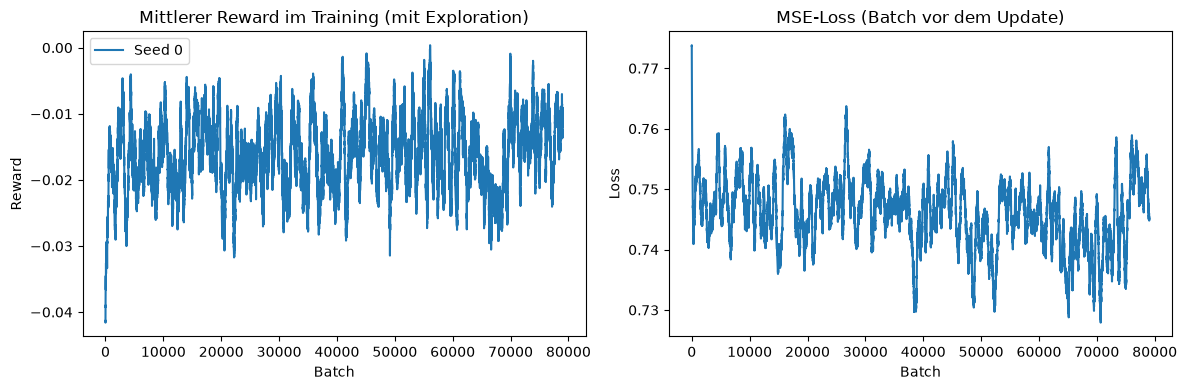

In [7]:
def moving_average(x, window=500):
    return np.convolve(x, np.ones(window) / window, mode="valid")


fig, (ax_reward, ax_loss) = plt.subplots(1, 2, figsize=(12, 4))
for seed in SEEDS:
    ax_reward.plot(moving_average(rewards[seed]), label=f"Seed {seed}")
    ax_loss.plot(moving_average(losses[seed]), label=f"Seed {seed}")
ax_reward.set(title="Mittlerer Reward im Training (mit Exploration)", xlabel="Batch", ylabel="Reward")
ax_loss.set(title="MSE-Loss (Batch vor dem Update)", xlabel="Batch", ylabel="Loss")
ax_reward.legend()
plt.tight_layout()
plt.show()